In [1]:
# IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual theme
sns.set_theme(style="whitegrid", context="notebook")

# Improve chart appearance
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# LOAD THE DATASET

df = pd.read_csv("student_habits_performance.csv")

# Display the first five records
print("FIRST FIVE STUDENTS")
display(df.head())

# Display the last five records
print("LAST FIVE STUDENTS")
display(df.tail())

FIRST FIVE STUDENTS


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


LAST FIVE STUDENTS


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
995,S1995,21,Female,2.6,0.5,1.6,No,77.0,7.5,Fair,2,High School,Good,6,Yes,76.1
996,S1996,17,Female,2.9,1.0,2.4,Yes,86.0,6.8,Poor,1,High School,Average,6,Yes,65.9
997,S1997,20,Male,3.0,2.6,1.3,No,61.9,6.5,Good,5,Bachelor,Good,9,Yes,64.4
998,S1998,24,Male,5.4,4.1,1.1,Yes,100.0,7.6,Fair,0,Bachelor,Average,1,No,69.7
999,S1999,19,Female,4.3,2.9,1.9,No,89.4,7.1,Good,2,Bachelor,Average,8,No,74.9


In [3]:
# UNDERSTAND THE DATASET

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-missing values
print("\nDataset information:")
df.info()

# Statistical summary
print("\nNumerical summary:")
display(df.describe().round(2))

Dataset shape: (1000, 16)

Column names:
['student_id', 'age', 'gender', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'part_time_job', 'attendance_percentage', 'sleep_hours', 'diet_quality', 'exercise_frequency', 'parental_education_level', 'internet_quality', 'mental_health_rating', 'extracurricular_participation', 'exam_score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 no

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.50,3.55,2.51,1.82,84.13,6.47,3.04,5.44,69.60
std,2.31,1.47,1.17,1.08,9.40,1.23,2.03,2.85,16.89
min,17.00,0.00,0.00,0.00,56.00,3.20,0.00,1.00,18.40
25%,18.75,2.60,1.70,1.00,78.00,5.60,1.00,3.00,58.48
50%,20.00,3.50,2.50,1.80,84.40,6.50,3.00,5.00,70.50
75%,23.00,4.50,3.30,2.52,91.02,7.30,5.00,8.00,81.32
max,24.00,8.30,7.20,5.40,100.00,10.00,6.00,10.00,100.00


In [5]:
#CHECK DATA QUALITY

# Count missing values
missing_values = df.isnull().sum()

print("MISSING VALUES")
print(missing_values[missing_values > 0])

# Count duplicate rows
print("\nDuplicate records:", df.duplicated().sum())

# Calculate missing-value percentages
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print("\nMissing-value percentages:")
print(missing_percentage[missing_percentage > 0])

MISSING VALUES
parental_education_level    91
dtype: int64

Duplicate records: 0

Missing-value percentages:
parental_education_level    9.1
dtype: float64


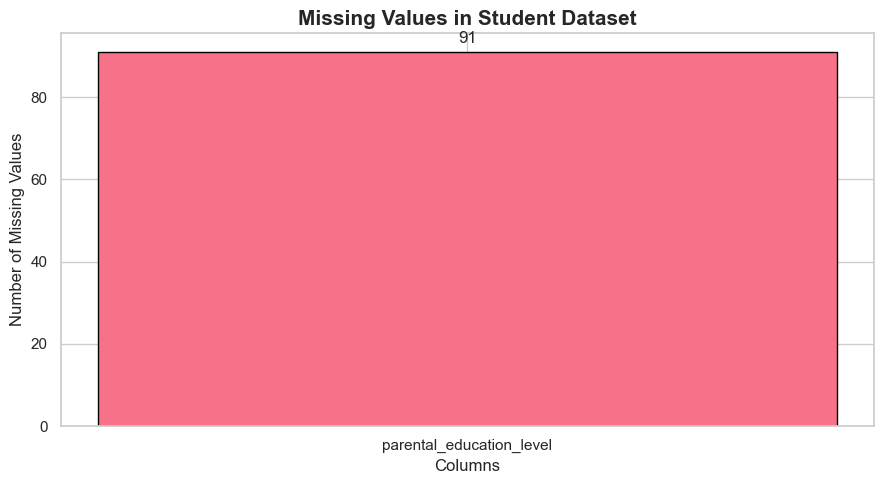

In [6]:
# VISUALIZATION MISSING VALUES

missing = df.isnull().sum()
missing = missing[missing > 0]

if not missing.empty:

    colors = sns.color_palette("husl", len(missing))

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        missing.index,
        missing.values,
        color=colors,
        edgecolor="black"
    )

    plt.title("Missing Values in Student Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")

    plt.bar_label(bars, padding=4)

    plt.tight_layout()
    plt.show()

else:
    print("No missing values found.")

In [7]:
# SEPARATE NUMERICAL AND CATEGORICAL COLUMNS

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("NUMERICAL COLUMNS")
print(numerical_columns)

print("\nCATEGORICAL COLUMNS")
print(categorical_columns)

NUMERICAL COLUMNS
['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating', 'exam_score']

CATEGORICAL COLUMNS
['student_id', 'gender', 'part_time_job', 'diet_quality', 'parental_education_level', 'internet_quality', 'extracurricular_participation']


### Analyze the Distribution of Examination Scores

We want to understand how students perform academically.

We will calculate the average, median, highest, and lowest examination scores.

In [8]:
#EXAMINATION SCORE SUMMARY

scores = df["exam_score"]

print("Average score:", round(scores.mean(), 2))
print("Median score:", round(scores.median(), 2))
print("Highest score:", round(scores.max(), 2))
print("Lowest score:", round(scores.min(), 2))
print("Standard deviation:", round(scores.std(), 2))

Average score: 69.6
Median score: 70.5
Highest score: 100.0
Lowest score: 18.4
Standard deviation: 16.89


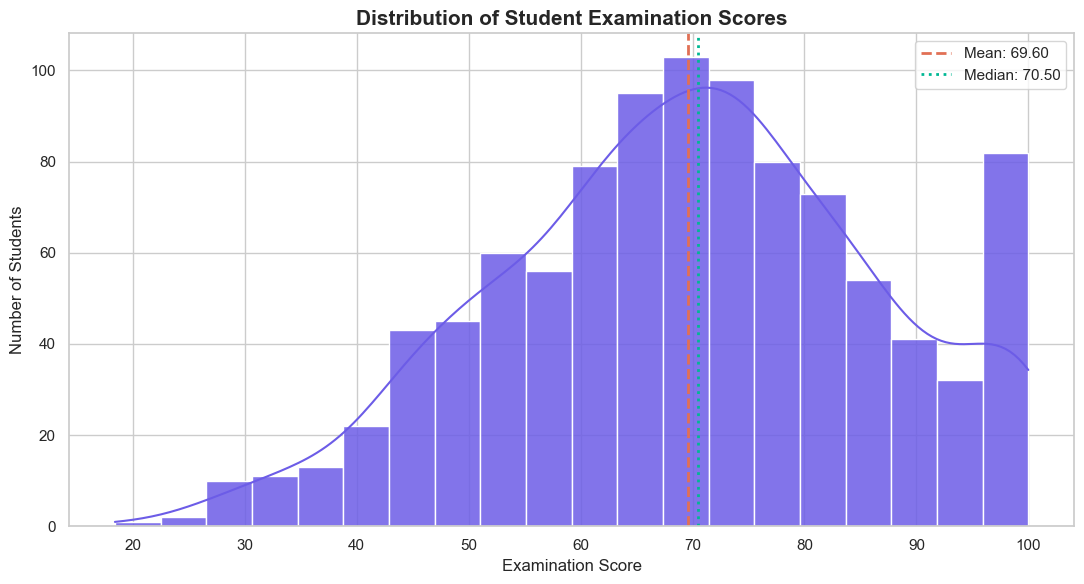

In [9]:
#EXAMINATION SCORE DISTRIBUTION

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="exam_score",
    bins=20,
    kde=True,
    color="#6C5CE7",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    scores.mean(),
    color="#E17055",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {scores.mean():.2f}"
)

plt.axvline(
    scores.median(),
    color="#00B894",
    linestyle=":",
    linewidth=2,
    label=f"Median: {scores.median():.2f}"
)

plt.title("Distribution of Student Examination Scores")
plt.xlabel("Examination Score")
plt.ylabel("Number of Students")
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation

The average examination score in your dataset is approximately 69.60 out of 100.

The histogram will show whether scores cluster around the middle, spread across a broad range, or concentrate near the highest or lowest values.

### Problem to investigate

Some students perform much better than others.

We need to identify the habits associated with these differences rather than assuming every student faces the same challenges.

In [10]:
#CREATE PERFORMANCE CATEGORIES

df["performance_band"] = pd.cut(
    df["exam_score"],
    bins=[-np.inf, 50, 70, 85, np.inf],
    labels=["Low", "Moderate", "Good", "Excellent"],
    right=False
)

# Count students in each category
performance_counts = (
    df["performance_band"]
    .value_counts()
    .reindex(["Low", "Moderate", "Good", "Excellent"])
)

print("STUDENT PERFORMANCE CATEGORIES")
display(performance_counts.to_frame("Number of Students"))

STUDENT PERFORMANCE CATEGORIES


,Number of Students
performance_band,
Low,131
Moderate,358
Good,323
Excellent,188


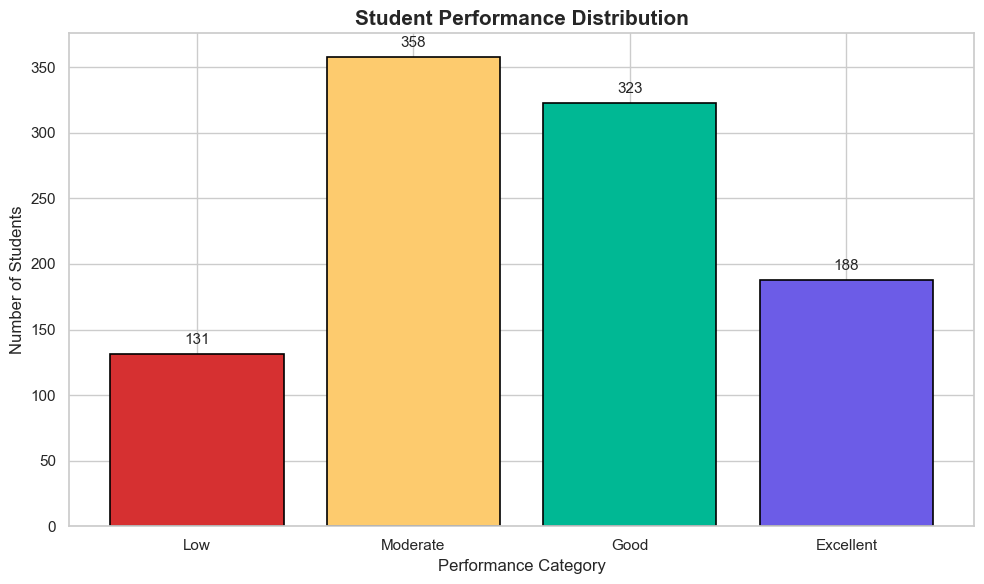

In [11]:
#PERFORMANCE DISTRIBUTION

labels = ["Low", "Moderate", "Good", "Excellent"]

counts = (
    df["performance_band"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

colors = [
    "#D63031",
    "#FDCB6E",
    "#00B894",
    "#6C5CE7"
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    labels,
    counts.values,
    color=colors,
    edgecolor="black",
    linewidth=1.2
)

plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.bar_label(bars, padding=5, fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation

This chart shows the number of students in each academic performance group.

It can help a school decide whether to prioritize remedial lessons, general revision support, advanced learning opportunities, or a combination of these interventions.

### What are we doing?

We want to determine whether students who study longer tend to achieve higher examination scores.

In [12]:
#ANALYZE STUDY HOURS

study_correlation = df[
    "study_hours_per_day"
].corr(df["exam_score"])

print(
    "Correlation between study hours and exam score:",
    round(study_correlation, 3)
)

# Average exam score by study time
study_summary = df.groupby(
    "study_hours_per_day"
)["exam_score"].mean()

print("\nAverage scores by recorded study hours:")
display(study_summary.round(2))

Correlation between study hours and exam score: 0.825

Average scores by recorded study hours:


study_hours_per_day
0.0     40.81
0.1     53.40
0.2     31.50
0.3     32.62
0.5     39.52
        ...  
7.4     99.23
7.5    100.00
7.6    100.00
8.2    100.00
8.3    100.00
Name: exam_score, Length: 78, dtype: float64

In [13]:
# CREATE STUDY-TIME GROUPS

df["study_group"] = pd.cut(
    df["study_hours_per_day"],
    bins=[-np.inf, 2, 4, 6, np.inf],
    labels=[
        "2 hours or less",
        "More than 2–4 hours",
        "More than 4–6 hours",
        "More than 6 hours"
    ],
    right=True
)

# Calculate the average score in each group
study_group_summary = df.groupby(
    "study_group",
    observed=False
)["exam_score"].mean()

print("AVERAGE EXAM SCORE BY STUDY GROUP")
display(study_group_summary.round(2))

AVERAGE EXAM SCORE BY STUDY GROUP


study_group
2 hours or less        46.97
More than 2–4 hours    65.96
More than 4–6 hours    82.05
More than 6 hours      97.77
Name: exam_score, dtype: float64

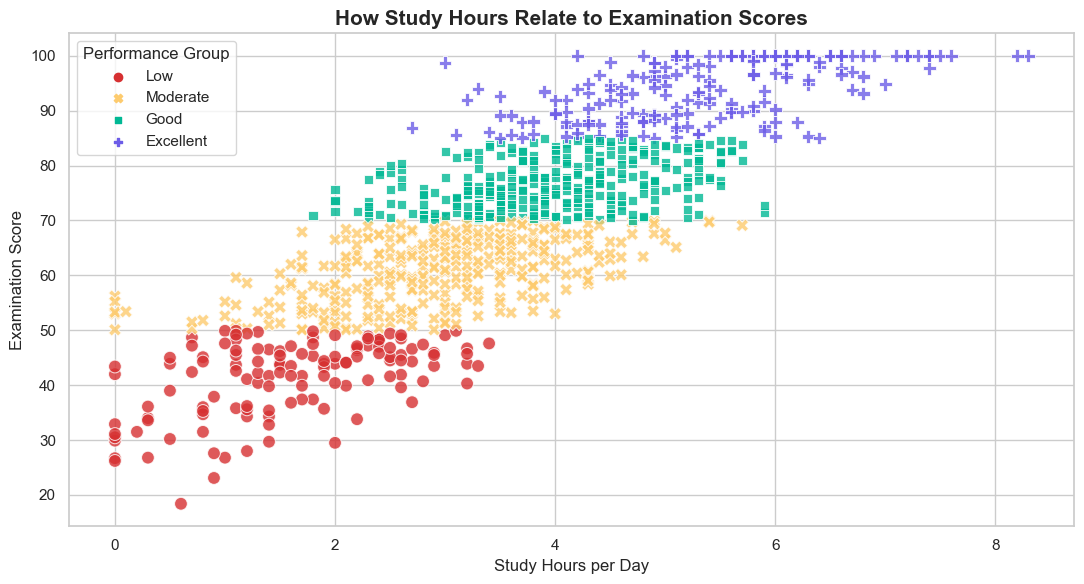

In [14]:
# VISUALIZATION STUDY HOURS AND PERFORMANCE

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="study_hours_per_day",
    y="exam_score",
    hue="performance_band",
    style="performance_band",
    palette={
        "Low": "#D63031",
        "Moderate": "#FDCB6E",
        "Good": "#00B894",
        "Excellent": "#6C5CE7"
    },
    s=85,
    alpha=0.8
)

plt.title("How Study Hours Relate to Examination Scores")
plt.xlabel("Study Hours per Day")
plt.ylabel("Examination Score")
plt.legend(title="Performance Group")

plt.tight_layout()
plt.show()

### Interpretation

The earlier analysis found a strong positive correlation of approximately 0.83 between study hours and examination scores.

This means students who reported studying longer generally achieved higher scores in this dataset.

However, the result does not prove that study duration alone causes better performance.

### Recommended solution

Students can improve their learning routines by:

Creating realistic study timetables.
Practising past examination questions.
Using active recall and spaced revision.
Seeking assistance with difficult subjects.
Reviewing their progress weekly.

## Analyze Social Media and Netflix Usage

We will investigate whether entertainment screen time is associated with examination scores.

In [15]:
# ANALYZE SCREEN TIME

screen_time_columns = [
    "social_media_hours",
    "netflix_hours"
]

for column in screen_time_columns:

    correlation = df[column].corr(df["exam_score"])

    print(
        f"{column} correlation with exam score:",
        round(correlation, 3)
    )

social_media_hours correlation with exam score: -0.167
netflix_hours correlation with exam score: -0.172


### Screen Time and Examination Scores

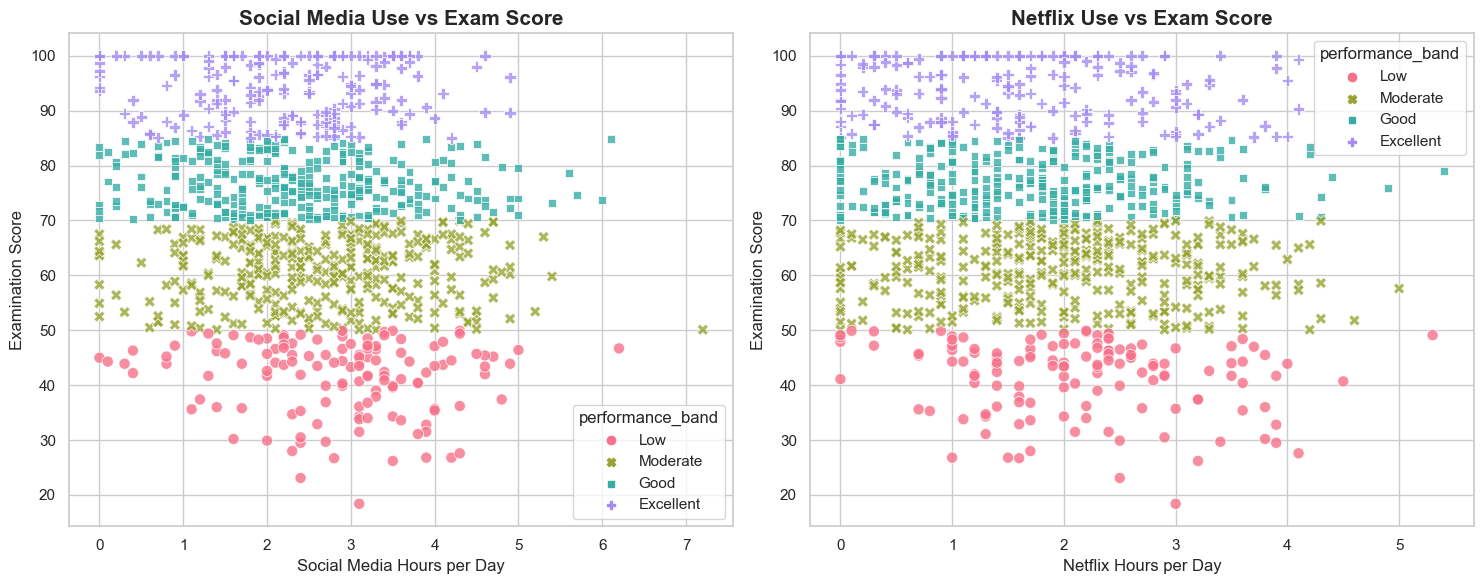

In [16]:
#SCREEN TIME SCATTER PLOTS

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df,
    x="social_media_hours",
    y="exam_score",
    hue="performance_band",
    style="performance_band",
    palette="husl",
    s=65,
    alpha=0.8,
    ax=axes[0]
)

axes[0].set_title("Social Media Use vs Exam Score")
axes[0].set_xlabel("Social Media Hours per Day")
axes[0].set_ylabel("Examination Score")

sns.scatterplot(
    data=df,
    x="netflix_hours",
    y="exam_score",
    hue="performance_band",
    style="performance_band",
    palette="husl",
    s=65,
    alpha=0.8,
    ax=axes[1]
)

axes[1].set_title("Netflix Use vs Exam Score")
axes[1].set_xlabel("Netflix Hours per Day")
axes[1].set_ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Interpretation

The previous analysis found weak negative correlations between entertainment screen time and examination scores.

The correlations were approximately:

Social media: -0.17.
Netflix: -0.17.

These findings suggest a modest negative relationship.

### Recommended solution

Students should monitor their screen time, reduce unnecessary distractions during study sessions, and schedule entertainment around academic responsibilities.

The objective is to develop balance, not eliminate all recreational activities.

## Analyze Sleep and Examination Performance

We will investigate whether sleep duration is associated with examination scores.

Sleep is important for general wellbeing, concentration, and learning.

In [17]:
# ANALYZE SLEEP

print(
    "Average sleep hours:",
    round(df["sleep_hours"].mean(), 2)
)

print(
    "Sleep and exam-score correlation:",
    round(
        df["sleep_hours"].corr(df["exam_score"]),
        3
    )
)

Average sleep hours: 6.47
Sleep and exam-score correlation: 0.122


### Visualization Sleep Distribution

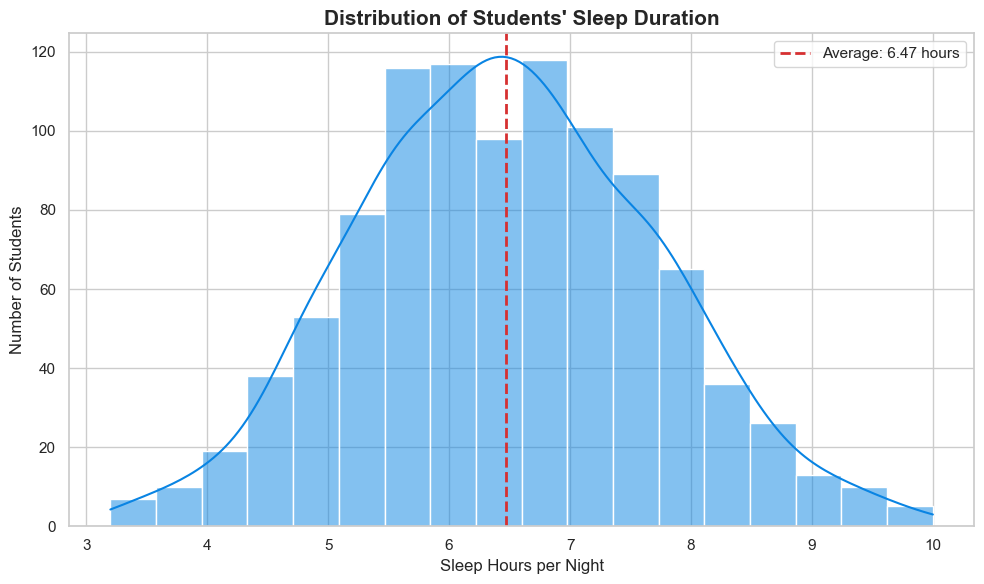

In [18]:
# VISUALIZATION SLEEP DURATION

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sleep_hours",
    bins=18,
    kde=True,
    color="#0984E3",
    edgecolor="white"
)

plt.axvline(
    df["sleep_hours"].mean(),
    color="#D63031",
    linestyle="--",
    linewidth=2,
    label=f"Average: {df['sleep_hours'].mean():.2f} hours"
)

plt.title("Distribution of Students' Sleep Duration")
plt.xlabel("Sleep Hours per Night")
plt.ylabel("Number of Students")
plt.legend()

plt.tight_layout()
plt.show()

### Sleep and Examination Scores

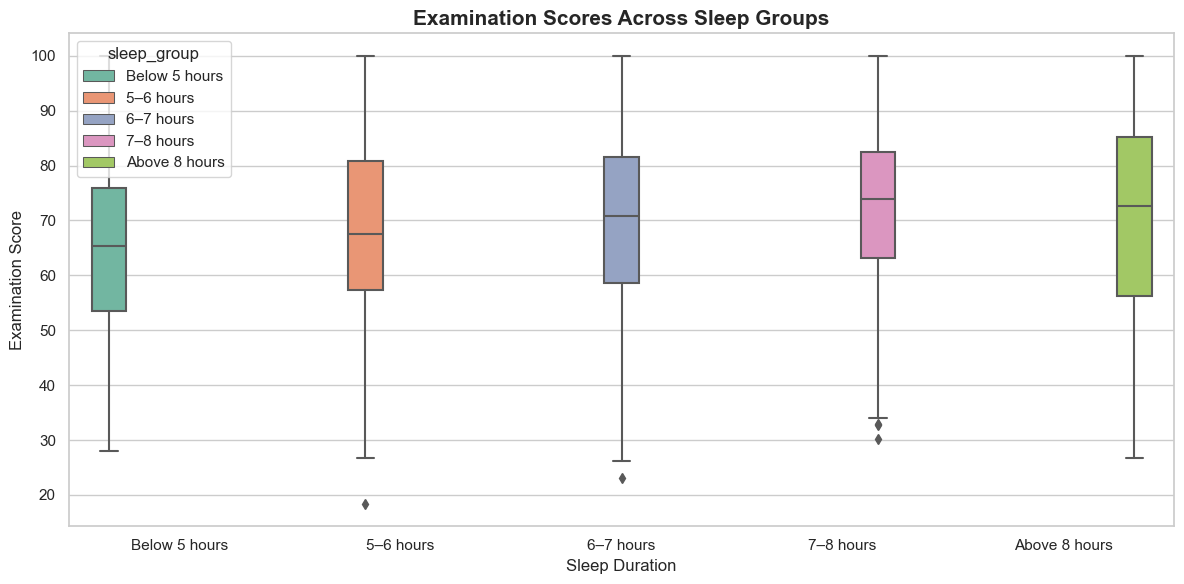

In [20]:
# VISUALIZATION SLEEP GROUPS AND PERFORMANCE

df["sleep_group"] = pd.cut(
    df["sleep_hours"],
    bins=[-np.inf, 5, 6, 7, 8, np.inf],
    labels=[
        "Below 5 hours",
        "5–6 hours",
        "6–7 hours",
        "7–8 hours",
        "Above 8 hours"
    ]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="sleep_group",
    y="exam_score",
    hue="sleep_group",
    palette="Set2",
    #legend=False
)

plt.title("Examination Scores Across Sleep Groups")
plt.xlabel("Sleep Duration")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Recommended solution

Students should establish consistent sleep schedules and avoid sacrificing sleep unnecessarily to study late into the night.

For adults, 7–9 hours is a common recommendation; teenagers aged 17 generally need 8–10 hours.

## Analyze Mental Health Ratings

We will investigate whether recorded mental health ratings are associated with academic performance.

The dataset records ratings on a scale from 1 to 10.

These ratings should not be treated as clinical diagnoses.

In [21]:
# ANALYZE MENTAL HEALTH RATINGS

print(
    "Average mental health rating:",
    round(df["mental_health_rating"].mean(), 2)
)

print(
    "Mental health and exam-score correlation:",
    round(
        df["mental_health_rating"].corr(df["exam_score"]),
        3
    )
)

Average mental health rating: 5.44
Mental health and exam-score correlation: 0.322


In [22]:
#Create mental health groups
# GROUP MENTAL HEALTH RATINGS

df["mental_health_group"] = pd.cut(
    df["mental_health_rating"],
    bins=[0, 3, 6, 10],
    labels=["Low rating", "Middle rating", "High rating"]
)

mental_health_summary = df.groupby(
    "mental_health_group",
    observed=False
)["exam_score"].mean()

print("AVERAGE SCORE BY MENTAL HEALTH RATING")
display(mental_health_summary.round(2))

AVERAGE SCORE BY MENTAL HEALTH RATING


mental_health_group
Low rating       63.43
Middle rating    67.87
High rating      75.90
Name: exam_score, dtype: float64

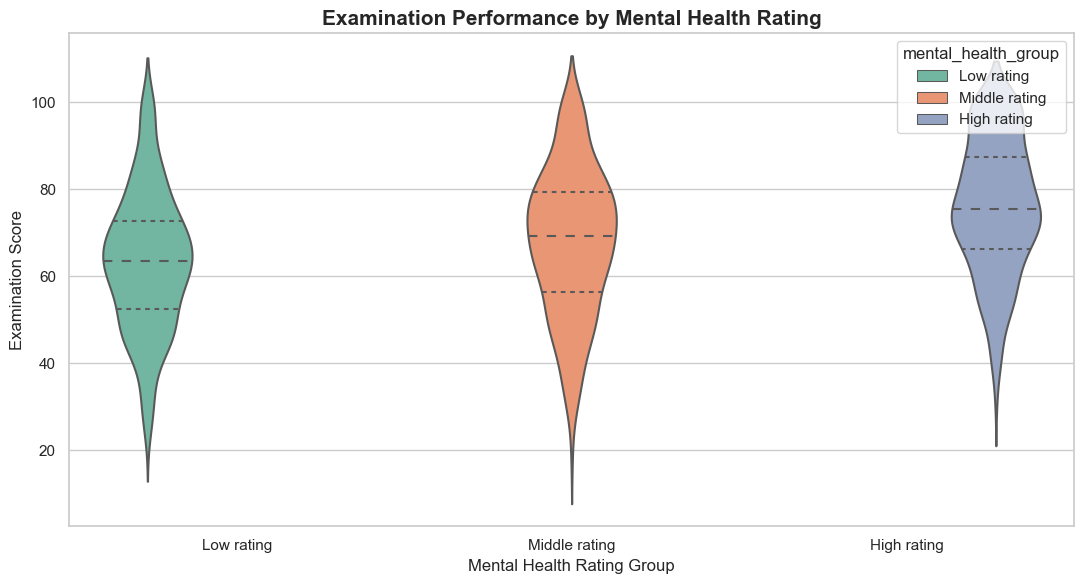

In [23]:
# VISUALIZATION VIOLIN PLOT

plt.figure(figsize=(11, 6))

sns.violinplot(
    data=df,
    x="mental_health_group",
    y="exam_score",
    hue="mental_health_group",
    palette="Set2",
    inner="quartile",
    legend=False
)

plt.title("Examination Performance by Mental Health Rating")
plt.xlabel("Mental Health Rating Group")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Recommended solution

Schools should provide appropriate counselling, supportive learning environments, and manageable academic expectations.

Students who are struggling should have opportunities to seek help without stigma.

## Analyze Attendance

Attendance can influence students' opportunities to participate in lessons and receive feedback.

We will examine its relationship with examination scores.

In [24]:
#STEP ANALYZE ATTENDANCE

print(
    "Average attendance:",
    round(df["attendance_percentage"].mean(), 2),
    "%"
)

print(
    "Attendance and exam-score correlation:",
    round(
        df["attendance_percentage"].corr(df["exam_score"]),
        3
    )
)

Average attendance: 84.13 %
Attendance and exam-score correlation: 0.09


### Attendance Versus Examination Scores

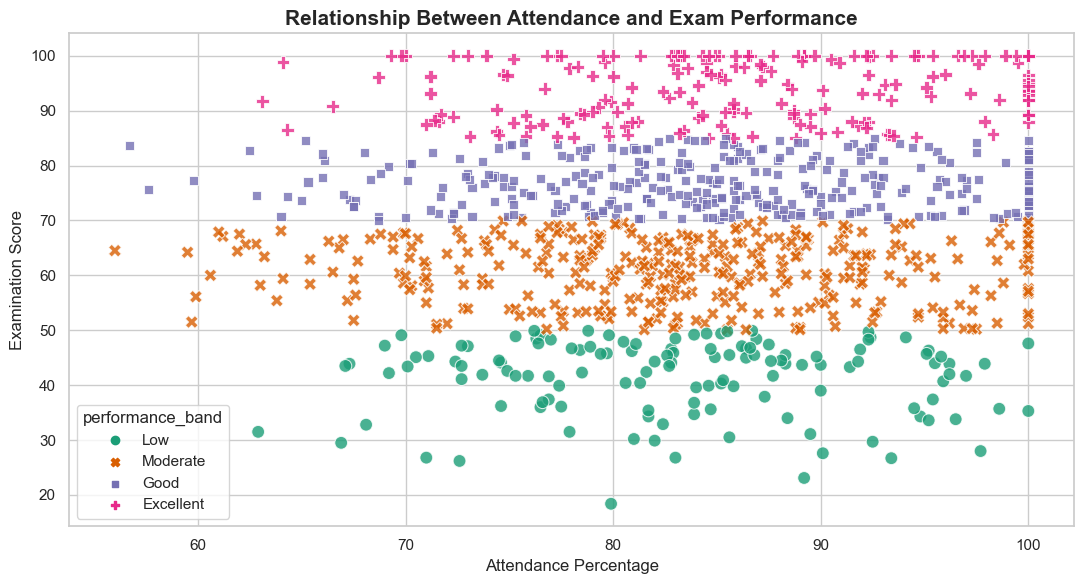

In [25]:
# VISUALIZATION ATTENDANCE SCATTER PLOT

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="attendance_percentage",
    y="exam_score",
    hue="performance_band",
    style="performance_band",
    palette="Dark2",
    s=85,
    alpha=0.8
)

plt.title("Relationship Between Attendance and Exam Performance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Recommended solution

Schools should investigate repeated absences, identify barriers to attendance, and provide suitable catch-up materials

## Analyze Diet Quality and Exercise

We will investigate students' reported diet quality and exercise frequency.

These factors are relevant to general health and wellbeing, although their relationships with examination scores may be influenced by other variables.

In [26]:
# STEP DIET AND EXERCISE ANALYSIS

print("DIET QUALITY COUNTS")
print(df["diet_quality"].value_counts())

print("\nAVERAGE SCORE BY DIET QUALITY")
display(
    df.groupby("diet_quality")["exam_score"]
    .mean()
    .round(2)
)

print("\nAVERAGE EXERCISE FREQUENCY")
print(round(df["exercise_frequency"].mean(), 2))

DIET QUALITY COUNTS
diet_quality
Fair    437
Good    378
Poor    185
Name: count, dtype: int64

AVERAGE SCORE BY DIET QUALITY


diet_quality
Fair    70.43
Good    69.37
Poor    68.13
Name: exam_score, dtype: float64


AVERAGE EXERCISE FREQUENCY
3.04


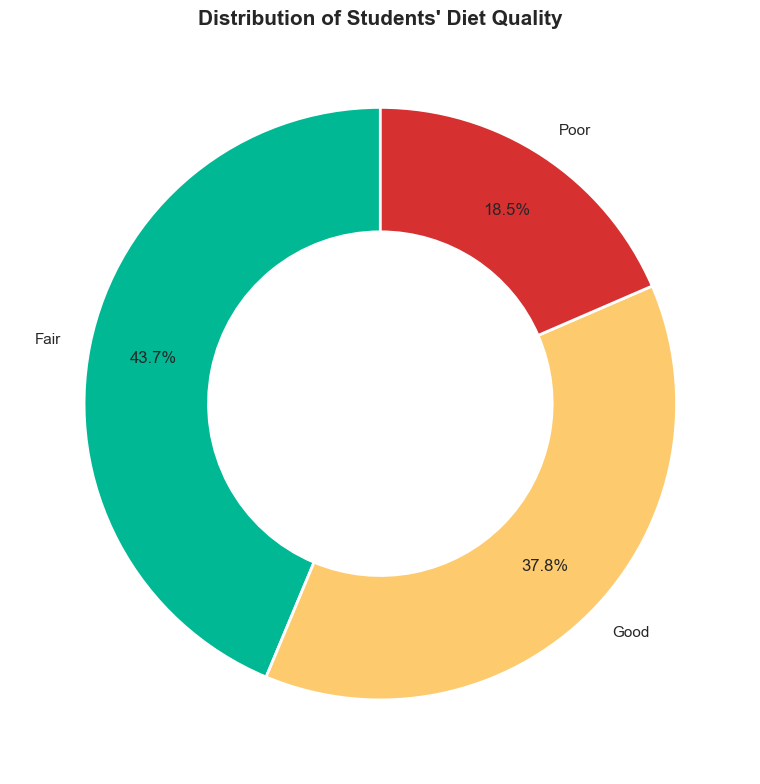

In [28]:
# VISUALIZATION DOUGHNUT CHART

diet_counts = df["diet_quality"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    diet_counts.values,
    labels=diet_counts.index,
    colors=["#00B894", "#FDCB6E", "#D63031"],
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": "white",
        "linewidth": 2
    }
)

plt.title("Distribution of Students' Diet Quality")
plt.tight_layout()
plt.show()

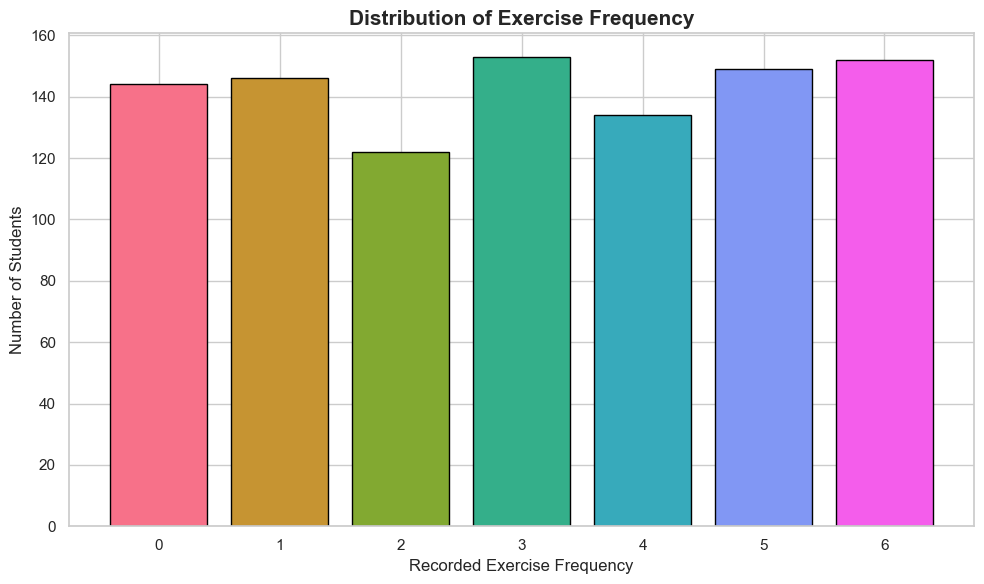

In [29]:
# VISUALIZATION EXERCISE FREQUENCY

exercise_counts = (
    df["exercise_frequency"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.bar(
    exercise_counts.index.astype(str),
    exercise_counts.values,
    color=sns.color_palette(
        "husl", len(exercise_counts)
    ),
    edgecolor="black"
)

plt.title("Distribution of Exercise Frequency")
plt.xlabel("Recorded Exercise Frequency")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

## Analyze Categorical Variables Using Colourful Bar Charts

We will explore the distribution of students across categories such as gender, internet quality, part-time job status, and extracurricular participation.

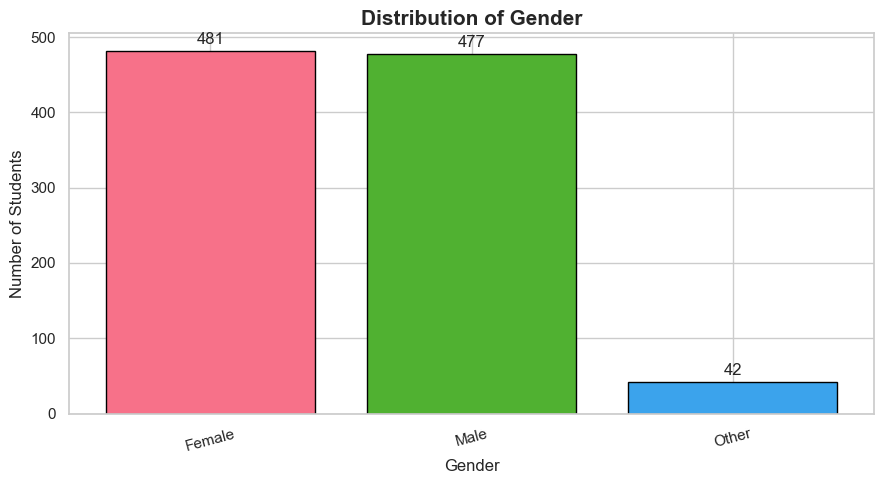

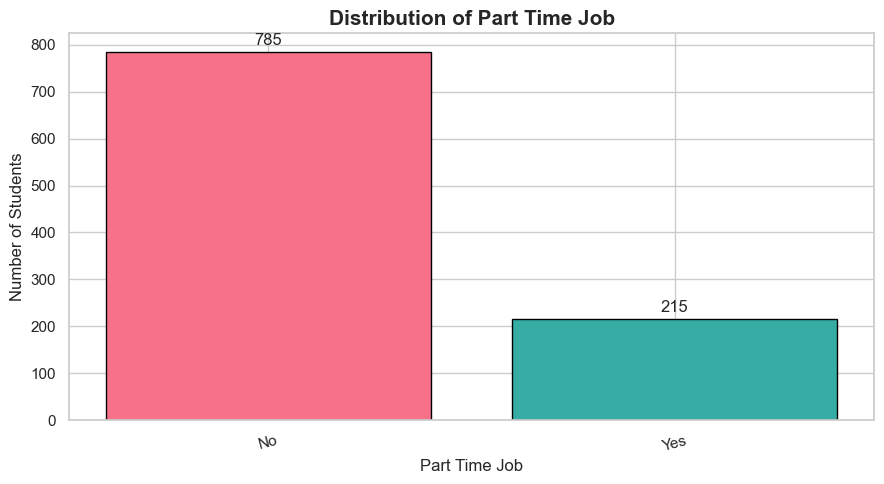

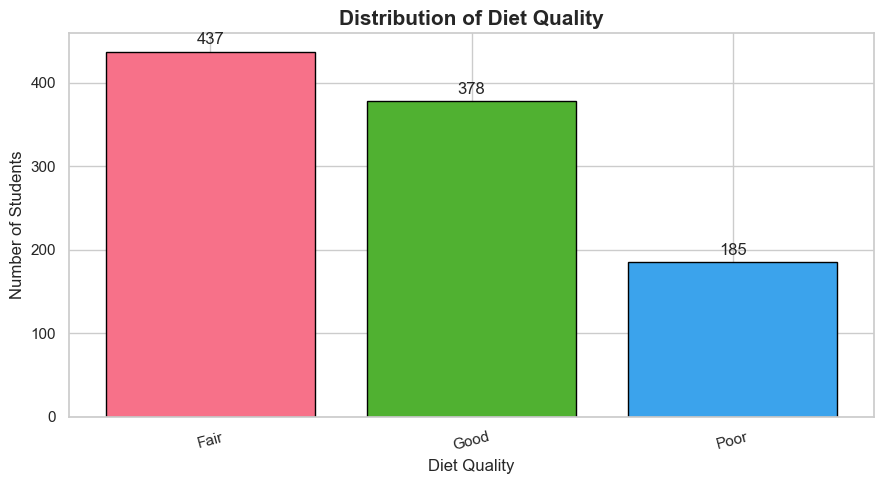

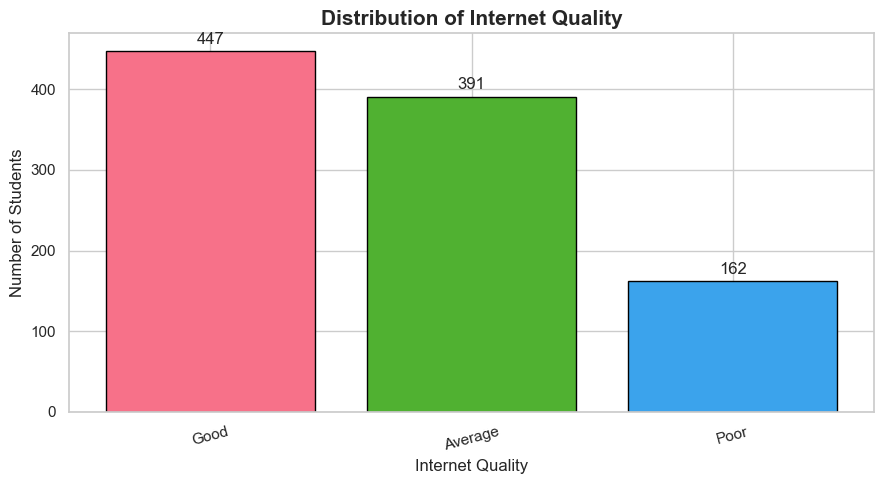

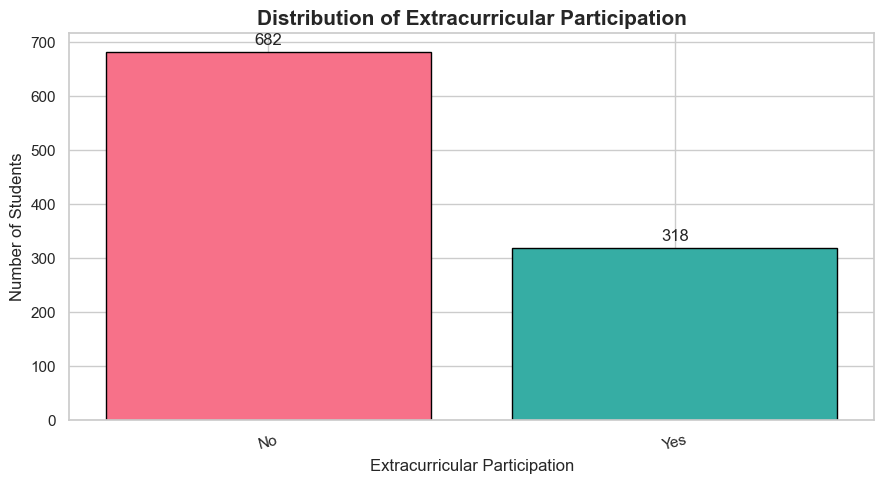

In [30]:
# STEP CATEGORICAL DATA ANALYSIS

categorical_to_plot = [
    "gender",
    "part_time_job",
    "diet_quality",
    "internet_quality",
    "extracurricular_participation"
]

for column in categorical_to_plot:

    counts = df[column].value_counts(dropna=False)

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        counts.index.astype(str),
        counts.values,
        color=sns.color_palette(
            "husl", len(counts)
        ),
        edgecolor="black"
    )

    plt.title(f"Distribution of {column.replace('_', ' ').title()}")
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Number of Students")

    plt.bar_label(bars, padding=3)

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### Recommended solution

These charts help schools understand the student population and identify categories that may deserve further investigation.

For example, internet quality may be relevant when designing online learning programmes, while extracurricular participation may be relevant when reviewing opportunities for student engagement.

## Investigate Parental Education and Part-Time Employment

In [31]:
# STEP PARENTAL EDUCATION

parent_summary = df.groupby(
    "parental_education_level",
    dropna=False
)["exam_score"].agg(
    ["count", "mean", "median"]
).round(2)

print("EXAM RESULTS BY PARENTAL EDUCATION")
display(parent_summary)

# PART-TIME EMPLOYMENT
job_summary = df.groupby(
    "part_time_job"
)["exam_score"].agg(
    ["count", "mean", "median"]
).round(2)

print("\nEXAM RESULTS BY PART-TIME JOB STATUS")
display(job_summary)

EXAM RESULTS BY PARENTAL EDUCATION


,count,mean,median
parental_education_level,,,
Bachelor,350,70.27,71.70
High School,392,69.55,69.95
Master,167,68.09,66.80
NaN,91,70.03,71.00



EXAM RESULTS BY PART-TIME JOB STATUS


,count,mean,median
part_time_job,,,
No,785,69.84,70.6
Yes,215,68.74,69.2


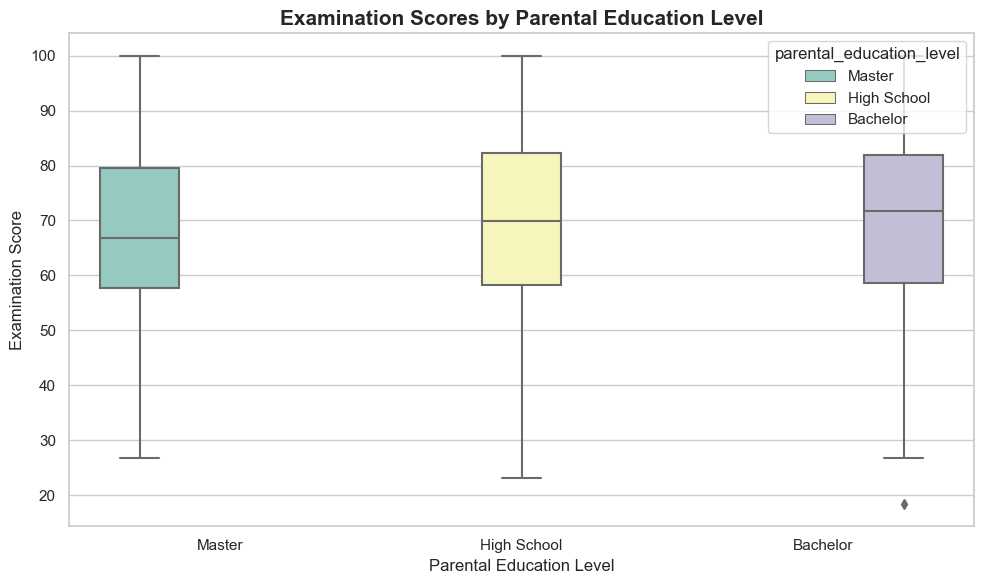

In [33]:
# VISUALIZATION PARENTAL EDUCATION

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="parental_education_level",
    y="exam_score",
    hue="parental_education_level",
    palette="Set3",
    #legend=False
)

plt.title("Examination Scores by Parental Education Level")
plt.xlabel("Parental Education Level")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Recommended solution

Students should receive support based on their learning needs rather than assumptions about their family background.

Schools can also investigate whether students need additional academic resources, mentoring, or learning opportunities.

## Create a Correlation Heatmap

In [34]:
# STEP CORRELATION ANALYSIS

numeric_df = df.select_dtypes(
    include=["number"]
).drop(
    columns=["student_id"],
    errors="ignore"
)

correlation_matrix = numeric_df.corr()

print("CORRELATION WITH EXAM SCORE")

display(
    correlation_matrix["exam_score"]
    .sort_values(ascending=False)
    .to_frame("Correlation")
    .round(3)
)

CORRELATION WITH EXAM SCORE


,Correlation
exam_score,1.000
study_hours_per_day,0.825
mental_health_rating,0.322
exercise_frequency,0.160
sleep_hours,0.122
attendance_percentage,0.090
age,-0.009
social_media_hours,-0.167
netflix_hours,-0.172


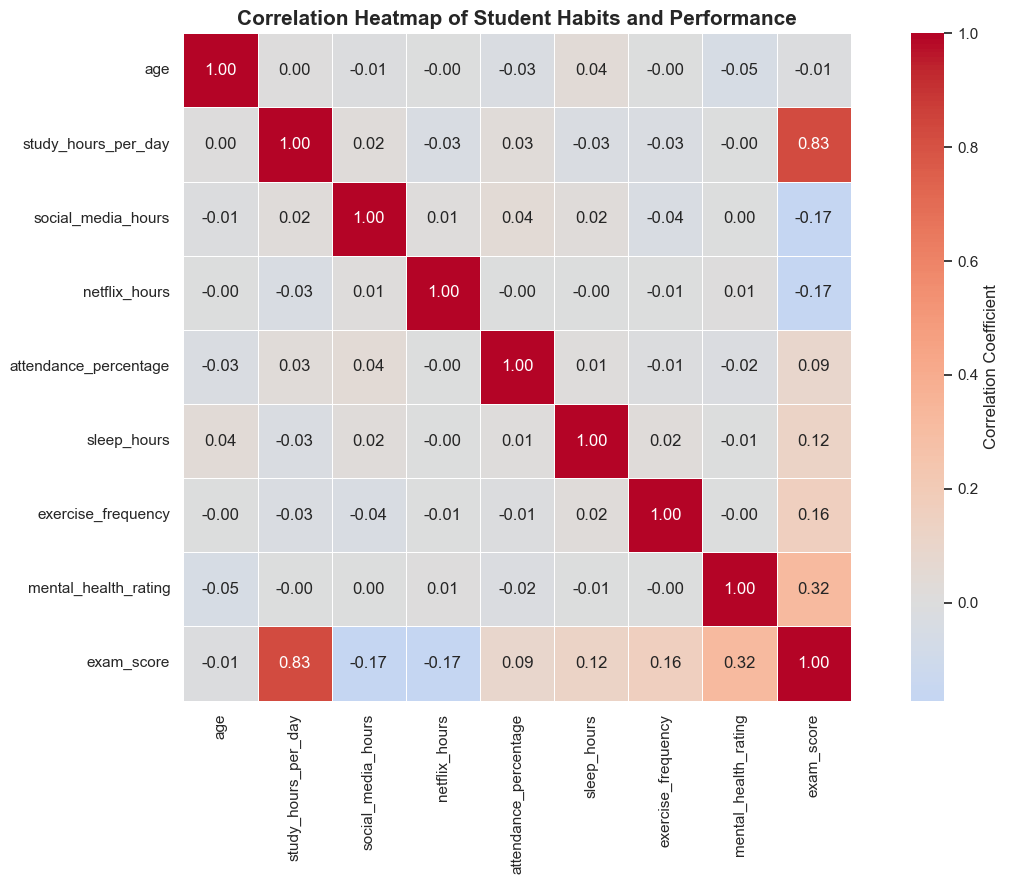

In [35]:
# VISUALIZATION CORRELATION HEATMAP

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Correlation Coefficient"
    }
)

plt.title("Correlation Heatmap of Student Habits and Performance")

plt.tight_layout()
plt.show()

### Important finding

The previous analysis found that study hours have the strongest positive linear relationship with examination scores among the measured variables.

This makes study habits an important area for further investigation.

However, correlation alone cannot establish that increasing study hours will cause a particular improvement in scores.

## Create a Bubble Chart

A bubble chart allows us to compare multiple numerical variables in one visualization.

In this example:

Horizontal axis: Study hours.
Vertical axis: Examination scores.
Bubble size: Attendance.
Bubble colour: Mental health rating.

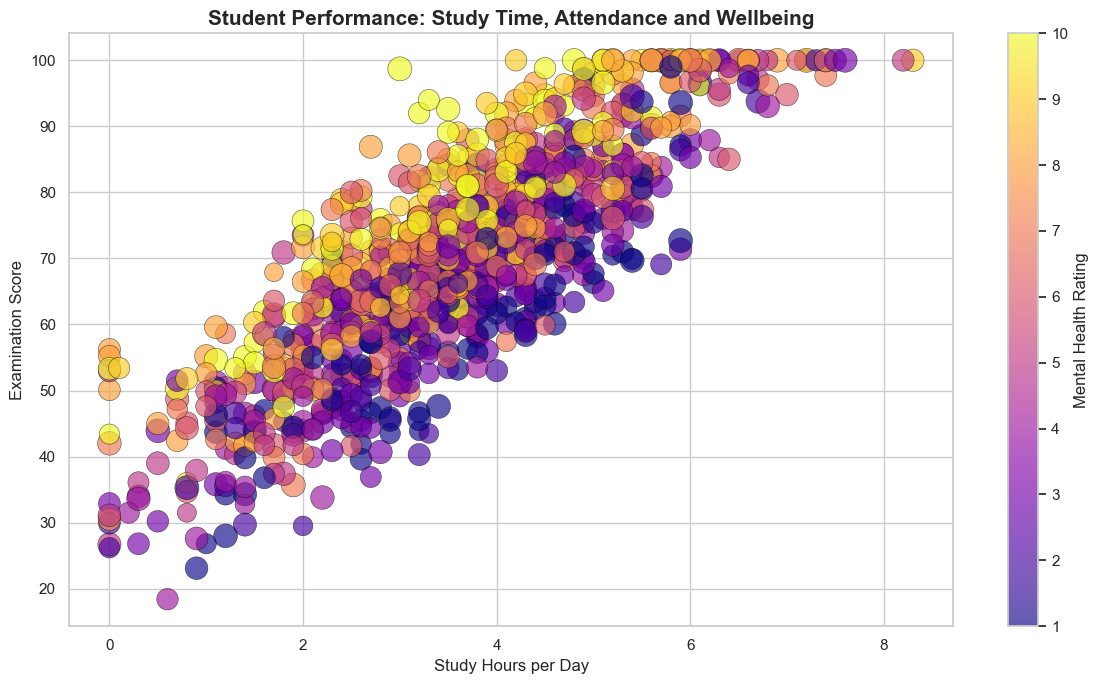

In [36]:
# STEP BUBBLE CHART

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    df["study_hours_per_day"],
    df["exam_score"],
    s=df["attendance_percentage"] * 3,
    c=df["mental_health_rating"],
    cmap="plasma",
    alpha=0.65,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(
    scatter,
    label="Mental Health Rating"
)

plt.title("Student Performance: Study Time, Attendance and Wellbeing")
plt.xlabel("Study Hours per Day")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

### Recommended solution

The bubble chart can help identify students whose academic performance and reported habits may warrant further examination.

It should not be used on its own to diagnose a problem or determine the cause of an individual student's performance.

## Create a Radar Chart

A radar chart is useful for comparing several average measurements on a single figure.

Here, we will compare the average characteristics of students in different performance groups.

Because the measurements use different scales, we must normalize them before plotting.

In [37]:
# STEP PREPARE DATA FOR A RADAR CHART

radar_columns = [
    "study_hours_per_day",
    "attendance_percentage",
    "sleep_hours",
    "exercise_frequency",
    "mental_health_rating"
]

# Calculate group averages
radar_data = df.groupby(
    "performance_band",
    observed=False
)[radar_columns].mean()

print("AVERAGE HABITS BY PERFORMANCE GROUP")
display(radar_data.round(2))

AVERAGE HABITS BY PERFORMANCE GROUP


,study_hours_per_day,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating
performance_band,,,,,
Low,1.62,83.30,6.35,2.43,3.85
Moderate,2.94,83.24,6.31,2.96,4.88
Good,3.97,84.47,6.56,3.07,5.89
Excellent,5.32,85.83,6.70,3.58,6.84


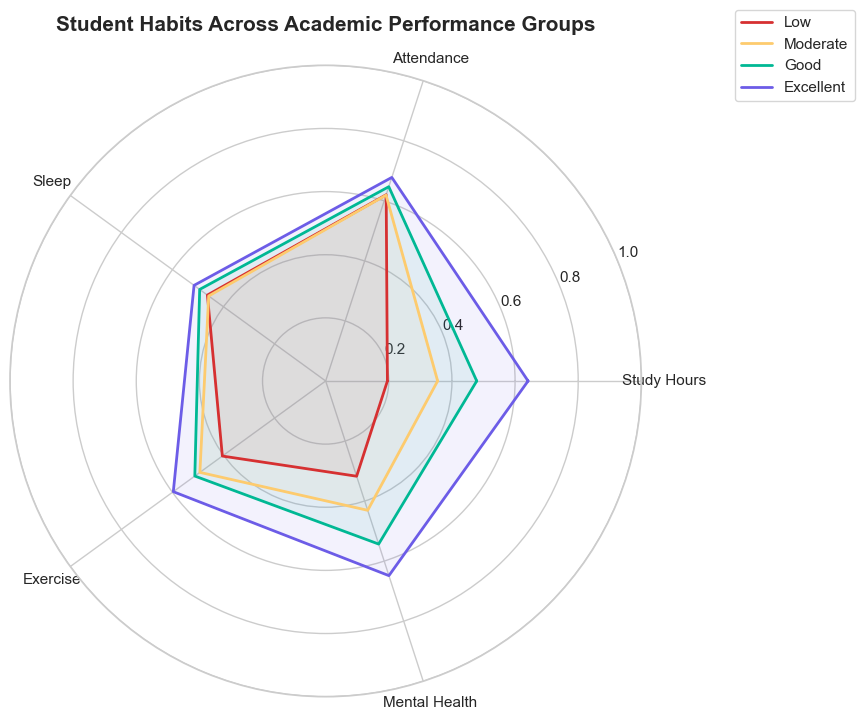

In [38]:
# VISUALIZATION RADAR CHART

# Normalize each measurement to a 0–1 scale
minimums = df[radar_columns].min()
maximums = df[radar_columns].max()

normalized = (
    radar_data - minimums
) / (
    maximums - minimums
).replace(0, 1)

categories = [
    "Study Hours",
    "Attendance",
    "Sleep",
    "Exercise",
    "Mental Health"
]

angles = np.linspace(
    0,
    2 * np.pi,
    len(categories),
    endpoint=False
).tolist()

# Close the radar chart
angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(9, 9),
    subplot_kw={"polar": True}
)

colors = [
    "#D63031",
    "#FDCB6E",
    "#00B894",
    "#6C5CE7"
]

for (group, row), color in zip(
    normalized.iterrows(), colors
):

    values = row.tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        color=color,
        label=group
    )

    ax.fill(
        angles,
        values,
        color=color,
        alpha=0.08
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

ax.set_ylim(0, 1)

plt.title(
    "Student Habits Across Academic Performance Groups",
    pad=25
)

plt.legend(
    loc="upper right",
    bbox_to_anchor=(1.35, 1.1)
)

plt.tight_layout()
plt.show()

The chart compares the relative levels of the five measurements across the performance groups.

Because each measurement is normalized separately, the chart compares relative positions within the dataset rather than the original units.

For example, a value of 0.8 does not mean 80% attendance. It represents a normalized value based on the minimum and maximum observed for that variable.

## Identify Students Who May Need Additional Support

We will identify students with examination scores below 50 and inspect their recorded habits.

This helps us move from general findings to potential individual support.

In [39]:
# STEP IDENTIFY STUDENTS WHO MAY NEED SUPPORT

students_needing_support = df[
    df["exam_score"] < 50
].copy()

columns_to_display = [
    "student_id",
    "study_hours_per_day",
    "attendance_percentage",
    "sleep_hours",
    "social_media_hours",
    "netflix_hours",
    "mental_health_rating",
    "exam_score"
]

print(
    "Number of students scoring below 50:",
    len(students_needing_support)
)

display(
    students_needing_support[
        columns_to_display
    ].sort_values("exam_score")
)

Number of students scoring below 50: 131


,student_id,study_hours_per_day,attendance_percentage,sleep_hours,social_media_hours,netflix_hours,mental_health_rating,exam_score
265,S1265,0.6,79.9,5.2,3.1,3.0,4,18.4
327,S1327,0.9,89.2,6.9,2.4,2.5,1,23.1
434,S1434,0.0,72.6,6.2,3.5,3.2,2,26.2
195,S1195,0.0,93.4,5.8,2.8,1.6,5,26.7
3,S1003,1.0,71.0,9.2,3.9,1.0,1,26.8
...,...,...,...,...,...,...,...,...
461,S1461,1.3,92.3,5.0,3.4,2.2,5,49.7
747,S1747,1.8,85.5,6.4,1.1,0.3,6,49.8
416,S1416,1.1,86.7,4.9,4.3,0.9,9,49.9
718,S1718,1.0,76.2,5.8,2.9,0.1,6,49.9


This creates a list of students whose scores may justify further academic review.

It does not establish why they received low scores.

For example, a student may need help with difficult subjects, learning resources, health-related challenges, or time management.

### Recommended solution

Teachers can use the information to organize supportive conversations, assess learning gaps, and develop personalized study plans.

The data should be handled confidentially and used to support students rather than label or stigmatize them.